# Assignment 3: SLCM Classification Analysis
**CS-430-01 Machine Learning | Programming Assignments**

| | |
|---|---|
| **Format** | Individual take-home Jupyter/Colab notebook |
| **Dataset** | SLCM_rent_arrears_student_clean.csv (same dataset as Assignment 2) |
| **Target variable** | `high_arrears`: 1 if `past_due_rent` is $3,000 or more; otherwise 0 |
| **Models** | Logistic Regression, KNN, Decision Tree, Random Forest, SVC |
| **Submission** | GitHub repository link submitted in Moodle |
| **Class follow-up** | Whole-class discussion; everyone participates |
| **Points** | 100 |

## Goal

In Assignment 2, you predicted the amount of overdue rent. Now the question is: Can household and housing information help identify households with $3,000 or more in past-due rent? Apply five classification models using the same prepared data. Focus on a fair comparison and a clear explanation of the results rather than complicated tuning.

## Notebook Instructions

- Copy each numbered question into a Markdown cell; answer beneath it in small code or Markdown cells.

- After important outputs and the chart, write 1–3 sentences of interpretation.

- Use the same 80/20 train/test split for all five models: `test_size=0.20, random_state=42, stratify=y`.

- Use the same preprocessing pipeline for each model; you may reuse the example from class.

- Do not use `record_id` or `past_due_rent` as model inputs. Run all cells and keep outputs visible.

## Setup

In [85]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [86]:
# Imports
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Assignment3/SLCM_rent_arrears_student_clean(2).csv")



# Part 1 – Understand the Classification Problem (15 points)

## 1. Explore the dataset (7 points)

- Load the CSV. Display five rows, the data shape, the column names, and missing-value counts.

In [87]:
df.head()

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1754 entries, 0 to 1753
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   record_id                   1754 non-null   object 
 1   adults_in_household         1754 non-null   int64  
 2   children_in_household       1754 non-null   int64  
 3   household_has_65plus        1754 non-null   object 
 4   monthly_household_income    1646 non-null   float64
 5   income_sources              1754 non-null   object 
 6   employment_status           1754 non-null   object 
 7   has_housing_voucher         1754 non-null   object 
 8   eviction_in_progress        1753 non-null   object 
 9   behind_on_utilities         1747 non-null   object 
 10  main_reason_behind_on_rent  1738 non-null   object 
 11  intake_quarter              1754 non-null   object 
 12  monthly_rent                1746 non-null   float64
 13  past_due_rent               1754 

- Identify one numerical and one categorical feature.

**My Response**


---


*   Numerical: adults_in_household
*   Categorical: record_id


- Answer: Why must `past_due_rent` be excluded from the input features?

**My Response**


---

It must be excluded because we're essentially pretending we never had it. Our goal is to use models approximate if they owe 3k or more by referring to a household's income. We'll create high_arrears (works as a simple bool, returning 1 if p_d_r is 3k or more, and 0 if not) in the next question to compare to the later models and see how close they get. It's like an answer key for a test, but in this case the answer key is high_arrears and the test takers are the models.

## 2. Create the target (8 points)

- Create `high_arrears`: 1 if `past_due_rent` is at least $3,000, otherwise 0.

In [89]:
#create high_arrears, 1 if past_due_rent is at least 3k and 0 o.w.
df['high_arrears'] = df['past_due_rent'].apply(lambda x: 1 if x >= 3000 else 0)
df.head()

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent,high_arrears
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0,1
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0,1
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0,1
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0,0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5,0


- Show class counts and one bar chart of `high_arrears`.

high_arrears
0    1210
1     544
Name: count, dtype: int64


<Axes: xlabel='high_arrears'>

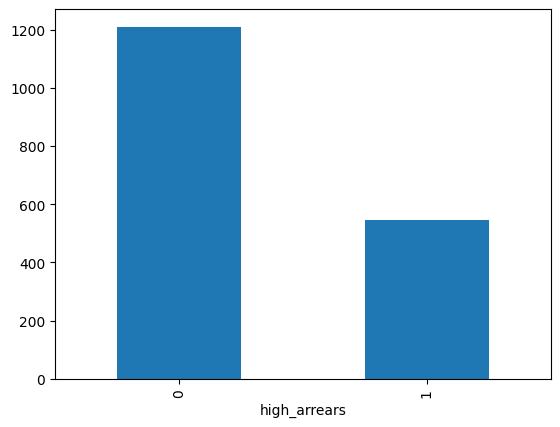

In [90]:
#show class counts and one bar chart of high_arrears
print(df['high_arrears'].value_counts())
df['high_arrears'].value_counts().plot(kind='bar')

- Answer: Which class is larger? Why might accuracy alone be misleading?

**My Response**


---

1. There are more that don't have past_due_rent >= 3000 than not, so class 0 is larger.

2. Accuracy alone may be misleading since it's just the amount of guesses that fit a certain criteria. The problem is that a model could favor one class more than another which doesn't give each class a fair shot, which then lessens the usefulness of the accuracy.

# Part 2 – Prepare the Data (25 points)

## 3. Select features and split (10 points)

- Create `X` by dropping `record_id`, `past_due_rent`, and `high_arrears`. Set `y = high_arrears`.

In [91]:
#follow the steps above and create X
X = df.drop(columns=['record_id', 'past_due_rent', 'high_arrears'])
y = df['high_arrears']

- Split the data once into training and testing sets.

In [92]:
#split the data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

- Answer: Why do we keep a separate test set?

**My Response**


---

We keep a test set to prevent overfitting, which is when a model may simply memorize the training data rather than find general patterns. Test sets are also useful because it gives the model more examples rather than just the one which allows us to see if it works for multiple models.

## 4. Build one reusable preprocessor (15 points)

- Identify numerical and categorical columns with `select_dtypes`.

In [93]:
#Identify the colums with select_dtypes
num_cols = X.select_dtypes(include=['number']).columns
cat_cols = X.select_dtypes(include=['object']).columns

- Numerical: fill missing values using median and apply `StandardScaler`.

In [94]:
#fill in missing values using median and apply standard scaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

- Categorical: fill missing values using most_frequent and apply `OneHotEncoder(handle_unknown="ignore")`.

In [95]:
#fill missing values
from sklearn.preprocessing import OneHotEncoder

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown="ignore"))
])

- Combine with `ColumnTransformer`. You may reuse the class example.

In [96]:
#combine with column transformer
from sklearn.compose import ColumnTransformer

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols),
])

- Answer: Why is scaling helpful for KNN and SVC?

**My Response**


---

Scaling prevents some columns from being overvalued by keeping every column on the same equal footing. EX: the columns `monthly-household_income` and `children_in_household` are measured differently (income in the hundereds and thousands, children in the first few numbers). If we don't scale, the income holds more weight even though having more children is technically the bigger weight. Scaling them brings their medians to about 0 and keeps both and the rest of the columns at the same weight.

Both KNN and SVC rely on distances as that is what they use primarily in their computation. KNN finds the closest distances between households, and if the columns aren't scaled, then the households that count as closest could be false or at the very least be distorted.

# Part 3 – Train and Compare Five Models (45 points)

## 5. Train the five classifiers (20 points)

- Build five pipelines with the same preprocessor, the same training set, and these models:

In [97]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

#build the five pipelines witht the same preprocessor and training set

- Logistic Regression: `LogisticRegression(max_iter=1000)`

In [98]:
#logic. regression
log_reg_pipeline = Pipeline([
    ('preprocessor', full_pipeline),
    ('classifier', LogisticRegression(max_iter=1000))
])

- KNN: `KNeighborsClassifier(n_neighbors=5)`

In [99]:
#Knn
knn_pipeline = Pipeline([
    ('preprocessor', full_pipeline),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

- Decision Tree: `DecisionTreeClassifier(max_depth=5, random_state=42)`

In [100]:
#Decision tree
dt_pipeline = Pipeline([
    ('preprocessor', full_pipeline),
    ('classifier', DecisionTreeClassifier(max_depth=5, random_state=42))
])

- Random Forest: `RandomForestClassifier(n_estimators=100, random_state=42)`

In [101]:
#random forest
rf_pipeline = Pipeline([
    ('preprocessor', full_pipeline),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

- Support Vector Classifier: `SVC()`

In [102]:
#svc
svc_pipeline = Pipeline([
    ('preprocessor', full_pipeline),
    ('classifier', SVC())
])

- Fit each pipeline and report test accuracy, recall, and F1 for class 1. Use a short, repeated code pattern; you do not need a loop or custom functions.

In [103]:
#fit each of the 5 pipelines and report what is says above

from sklearn.metrics import accuracy_score, recall_score, f1_score

#log. regression
log_reg_pipeline.fit(X_train, y_train)
log_reg_y_pred = log_reg_pipeline.predict(X_test)
log_reg_accuracy = accuracy_score(y_test, log_reg_y_pred)
log_reg_recall = recall_score(y_test, log_reg_y_pred)
log_reg_f1 = f1_score(y_test, log_reg_y_pred)
print(f'Logistic Regression Accuracy: {log_reg_accuracy}')
print(f'Logistic Regression Recall: {log_reg_recall}')
print(f'Logistic Regression F1: {log_reg_f1}')
print('\n')

#KNN
knn_pipeline.fit(X_train, y_train)
knn_y_pred = knn_pipeline.predict(X_test)
knn_accuracy = accuracy_score(y_test, knn_y_pred)
knn_recall = recall_score(y_test, knn_y_pred)
knn_f1 = f1_score(y_test, knn_y_pred)
print(f'KNN Accuracy: {knn_accuracy}')
print(f'KNN Recall: {knn_recall}')
print(f'KNN F1: {knn_f1}')
print('\n')

#Decision tree
dt_pipeline.fit(X_train, y_train)
dt_y_pred = dt_pipeline.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_y_pred)
dt_recall = recall_score(y_test, dt_y_pred)
dt_f1 = f1_score(y_test, dt_y_pred)
print(f'Decision Tree Accuracy: {dt_accuracy}')
print(f'Decision Tree Recall: {dt_recall}')
print(f'Decision Tree F1: {dt_f1}')
print('\n')

#Random forest
rf_pipeline.fit(X_train, y_train)
rf_y_pred = rf_pipeline.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_recall = recall_score(y_test, rf_y_pred)
rf_f1 = f1_score(y_test, rf_y_pred)
print(f'Random Forest Accuracy: {rf_accuracy}')
print(f'Random Forest Recall: {rf_recall}')
print(f'Random Forest F1: {rf_f1}')
print('\n')

#SVC
svc_pipeline.fit(X_train, y_train)
svc_y_pred = svc_pipeline.predict(X_test)
svc_accuracy = accuracy_score(y_test, svc_y_pred)
svc_recall = recall_score(y_test, svc_y_pred)
svc_f1 = f1_score(y_test, svc_y_pred)
print(f'SVC Accuracy: {svc_accuracy}')
print(f'SVC Recall: {svc_recall}')
print(f'SVC F1: {svc_f1}')

Logistic Regression Accuracy: 0.6951566951566952
Logistic Regression Recall: 0.30275229357798167
Logistic Regression F1: 0.3815028901734104


KNN Accuracy: 0.6809116809116809
KNN Recall: 0.3761467889908257
KNN F1: 0.422680412371134


Decision Tree Accuracy: 0.6951566951566952
Decision Tree Recall: 0.3302752293577982
Decision Tree F1: 0.4022346368715084


Random Forest Accuracy: 0.7037037037037037
Random Forest Recall: 0.3211009174311927
Random Forest F1: 0.40229885057471265


SVC Accuracy: 0.7065527065527065
SVC Recall: 0.22935779816513763
SVC F1: 0.32679738562091504


## 6. Compare the models (10 points)

- Put the test results in one table with columns: Model, Accuracy, Recall, F1.

In [104]:
#print the same 5 results i just printed but in a table this time
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'SVC'],
    'Accuracy': [log_reg_accuracy, knn_accuracy, dt_accuracy, rf_accuracy, svc_accuracy],
    'Recall': [log_reg_recall, knn_recall, dt_recall, rf_recall, svc_recall],
    'F1': [log_reg_f1, knn_f1, dt_f1, rf_f1, svc_f1]
})

results

,Model,Accuracy,Recall,F1
0,Logistic Regression,0.695157,0.302752,0.381503
1,KNN,0.680912,0.376147,0.422680
2,Decision Tree,0.695157,0.330275,0.402235
3,Random Forest,0.703704,0.321101,0.402299
4,SVC,0.706553,0.229358,0.326797


- Create one confusion matrix for the model with the highest test F1.

In [105]:
#create a confusion matrix for model KNN
from sklearn.metrics import confusion_matrix

knn_conf_matrix = confusion_matrix(y_test, knn_y_pred)
print(knn_conf_matrix)

[[198  44]
 [ 68  41]]


- Answer: Which model catches the highest proportion of high-arrears households? What does a missed case mean for SLCM?

**My Response**

---

`KNN` catches the highest proportion of high-arrears households. A missed case means that there are households in need of help that are wrongfully placed into the low-risk/stable category; a false negative.

## 7. Try a small GridSearchCV (15 points)

- Tune only two models on the training set with `cv=3` and `scoring="f1"`.

In [106]:
#tune models KNN and Decision Tree with training set w/ c=e and scoring = 'f1'
from sklearn.model_selection import GridSearchCV


- For KNN, try `n_neighbors = [3, 5, 7]`.

In [107]:
#for KNN
knn_param_grid = {'classifier__n_neighbors': [3, 5, 7]}
knn_grid_search = GridSearchCV(knn_pipeline, knn_param_grid, cv=3, scoring='f1')
knn_grid_search.fit(X_train, y_train)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['adults_in_household', 'children_in_household',
       'monthly_household_income', 'monthly_rent'],
      dtype='object')),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer...
                                                                                         ('encoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         Index(['household_has_65plus', 'income_sources', 'employment_status',
       'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities',
       'main_reason_behind_on_rent', 'intake_quarter'],
      dtype='object'))])),
                                       ('classifier', KNeighborsClassifier())]),
             param_grid={'classifier__n_neighbors': [3, 5, 7]}, scoring='f1')

- For Decision Tree, try `max_depth = [3, 5, None]`

In [108]:
#for decision tree
dt_param_grid = {'classifier__max_depth': [3, 5, None]}
dt_grid_search = GridSearchCV(dt_pipeline, dt_param_grid, cv=3, scoring='f1')
dt_grid_search.fit(X_train, y_train)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['adults_in_household', 'children_in_household',
       'monthly_household_income', 'monthly_rent'],
      dtype='object')),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer...
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         Index(['household_has_65plus', 'income_sources', 'employment_status',
       'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities',
       'main_reason_behind_on_rent', 'intake_quarter'],
      dtype='object'))])),
                                       ('classifier',
                                        DecisionTreeClassifier(max_depth=5,
                                                               random_state=42))]),
             param_grid={'classifier__max_depth': [3, 5, None]}, scoring='f1')

- Print `best_params_` and `best_score_` for each search. No extra charts or second search are needed.

In [109]:
#print best_params_ and best_score_ for each search
print(f'KNN Best Params: {knn_grid_search.best_params_}')
print(f'KNN Best Score: {knn_grid_search.best_score_}')

print(f'Decision Tree Best Params: {dt_grid_search.best_params_}')
print(f'Decision Tree Best Score: {dt_grid_search.best_score_}')

KNN Best Params: {'classifier__n_neighbors': 7}
KNN Best Score: 0.4854649923374277
Decision Tree Best Params: {'classifier__max_depth': None}
Decision Tree Best Score: 0.4569667651231481


- Answer: Which has the higher best cross-validation F1? Why is GridSearchCV fitted on training data only?

**My Response**


---


1. KNN has the higher best cross-validation F1 `~0.485` over Decision Tree `~0.457`
2. GridSearchCV needs to be fitted on only the training data to prevent any data leakage. The test set must remain untouched until all is set, but if we were to use that for fitting, the model would begin to overfit for the test set. It'll look really good until we try the model on other sets where it will fail or underpreform when it comes to generalizing.

# Part 4 – Explain the Results (15 points)

## 8. Interpret your comparison (8 points)

- In 4–5 sentences, identify the most promising model based on your results. Explain your choice using F1 and recall, not accuracy alone.

**My Response**


---

Based on the results, KMM seems to be the best fit. Although it scores lowest in terms of accuracy compared all other untunded models, it scores the highest in recall and F1. Then again, having a high accuracy is misleading here as the dataset is imbalanced.

- Did a more complex model necessarily perform better? What types of errors should SLCM pay attention to?

Having a more complex model didn't necessarily increase preformance. Random Forest and SVC both have the issue of misplacing households into false negatives. SLCM should prioritize the false-negatives which are those who need help but are put in as stable and low-risk by the models.

## 9. Recommendation to SLCM (7 points)

- Write 4–5 sentences for a non-technical SLCM audience: what you tried to predict, how well the selected model performed, one practical insight, and one limitation.

**My response**

---

We have developed machine learning models that identifies households in South Louisville that are at risk of needing to pay back high amounts of rent. The outpreforming model (KNN) correctly approximated about 38% of the households int the dataset, which means this can be used as an early screening process going forward, but it alone is not enough to find households that are high at risk. The model struggles in that it flags some false negatives, which are those who are at risk but are flagged as stable or low risk. As it stands, the model cannot find all at risk on its own, but it gives a good start.

- State that a prediction is not proof of cause and must not be used alone to decide eligibility for assistance.

**My response**

---

Predictions can never be proof of cause as they are simply predictions and cannot correctly consider every example. Sure they can help in that goal, but they must'nt be the primary way to achieve that goal.

## Grading
| Part | Points |
|---|---|
| Part 1 – Understand the Problem | 15 |
| Part 2 – Prepare the Data | 25 |
| Part 3 – Train and Compare Models | 45 |
| Part 4 – Explain Results | 15 |
| **Total** | **100** |

## What to Submit

- Completed .ipynb notebook with questions, code, interpretations, and visible outputs.

- Provided CSV and a short README in your GitHub repository. Submit the GitHub link in Moodle.

## Responsible Use of Data and AI

Respect the de-identified community data. Do not attempt to identify households. AI may help explain or debug code, but you must understand, verify, and disclose AI use. Your interpretations and class discussion must reflect your own understanding.